# **ML Assignment 1: Tabular Data**
**Dataset:** [Diabetes Health Indicators Dataset (BRFSS 2023 - `diabetes_012`)](https://www.kaggle.com/datasets/luisangelparra/diabetes-health-indicators-dataset)

> Set `TRAIN_MODEL = True` to train all models from scratch and save the results to `model_result_diabetes_012_v3.csv` (with tuned models + `tree_method="hist"` + batch size 256, this takes ~5-10 minutes on Colab GPU/CPU). Once saved, set `TRAIN_MODEL = False` to load saved results without retraining.

In [1]:
TRAIN_MODEL = True

# 1. Download and Import Data

In [2]:
!pip install -q kagglehub lightgbm
import kagglehub
import os

# Download latest version via kagglehub (Google Colab standard way)
path = kagglehub.dataset_download("luisangelparra/diabetes-health-indicators-dataset")
print("Path to dataset files:", path)
print("Files:", os.listdir(path))

100%|██████████| 6.44M/6.44M [00:00<00:00, 143MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/luisangelparra/diabetes-health-indicators-dataset/versions/1
Files: ['diabetes_binary_5050split_health_indicators_BRFSS2023.csv', 'diabetes_binary_health_indicators_BRFSS2023.csv', 'diabetes_012_health_indicators_BRFSS2023.csv']


In [3]:
import os
import glob
import math
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
warnings.simplefilter(action='ignore')
plt.style.use('seaborn-v0_8-deep')

# Locate and load ONLY the 012 file inside the kagglehub download directory
file_012_candidates = glob.glob(os.path.join(path, '**', '*012*.csv'), recursive=True)
if not file_012_candidates:
    all_files = glob.glob(os.path.join(path, '**', '*'), recursive=True)
    raise FileNotFoundError(f"Could not find the 012 CSV file in {path}. Found: {all_files}")

DATA_PATH = file_012_candidates[0]
print("Loading dataset:", DATA_PATH)

ds = pd.read_csv(DATA_PATH)
# backup
ds_backup = ds.copy()

Loading dataset: /root/.cache/kagglehub/datasets/luisangelparra/diabetes-health-indicators-dataset/versions/1/diabetes_012_health_indicators_BRFSS2023.csv


# 2. Exploratory Data Analysis

In [4]:
# dimensions of dataset
ds.shape

(261589, 23)

In [5]:
# summary of dataset
ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261589 entries, 0 to 261588
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          261589 non-null  float64
 1   KidneyDisease         261589 non-null  float64
 2   HighBP                261589 non-null  float64
 3   HighChol              261589 non-null  float64
 4   CholCheck             261589 non-null  float64
 5   Asthma                261589 non-null  float64
 6   COPD                  261589 non-null  float64
 7   BMI                   261589 non-null  float64
 8   Smoker                261589 non-null  float64
 9   Stroke                261589 non-null  float64
 10  HeartDiseaseorAttack  261589 non-null  float64
 11  PhysActivity          261589 non-null  float64
 12  HvyAlcoholConsump     261589 non-null  float64
 13  AnyHealthcare         261589 non-null  float64
 14  NoDocbcCost           261589 non-null  float64
 15  

In [6]:
# preview the dataset
ds.head()

,Diabetes_012,KidneyDisease,HighBP,HighChol,CholCheck,Asthma,COPD,BMI,Smoker,Stroke,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,AgeGroup,Education,Income
0,0.0,2.0,1.0,1.0,1.0,1.0,2.0,22.0,1.0,0.0,...,1.0,1.0,4.0,2.0,6.0,1.0,0.0,13.0,4.0,2.0
1,2.0,2.0,1.0,0.0,1.0,2.0,2.0,26.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,12.0,5.0,7.0
2,0.0,2.0,1.0,1.0,1.0,2.0,2.0,30.0,0.0,0.0,...,1.0,0.0,3.0,3.0,2.0,0.0,0.0,9.0,5.0,7.0
3,0.0,1.0,1.0,1.0,1.0,2.0,2.0,33.0,0.0,0.0,...,1.0,0.0,3.0,0.0,5.0,1.0,0.0,13.0,5.0,6.0
4,2.0,2.0,1.0,1.0,1.0,2.0,2.0,23.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,4.0,7.0


In [7]:
# All BRFSS 2023 columns are numerically encoded (float64),
# so we separate continuous numerical columns from binary/ordinal categorical columns
target_col = "Diabetes_012"
num_cols = pd.Index([c for c in ["BMI", "MentHlth", "PhysHlth"] if c in ds.columns])
cat_cols = ds.columns.drop(num_cols)

print("Target column:", target_col)
print("Continuous numerical columns:", list(num_cols))
print("Categorical / binary / ordinal columns:", list(cat_cols))

Target column: Diabetes_012
Continuous numerical columns: ['BMI', 'MentHlth', 'PhysHlth']
Categorical / binary / ordinal columns: ['Diabetes_012', 'KidneyDisease', 'HighBP', 'HighChol', 'CholCheck', 'Asthma', 'COPD', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'DiffWalk', 'Sex', 'AgeGroup', 'Education', 'Income']


In [8]:
# describe the dataset
# numerical cols
ds[num_cols].describe()

,BMI,MentHlth,PhysHlth
count,261589.000000,261589.000000,261589.000000
mean,28.824117,4.178471,4.400892
std,6.523703,8.055756,8.699962
min,12.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000
50%,28.000000,0.000000,0.000000
75%,32.000000,4.000000,4.000000
max,100.000000,30.000000,30.000000


In [9]:
# categorical cols
ds[cat_cols].astype('category').describe()

,Diabetes_012,KidneyDisease,HighBP,HighChol,CholCheck,Asthma,COPD,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,DiffWalk,Sex,AgeGroup,Education,Income
count,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0,261589.0
unique,3.0,4.0,2.0,2.0,2.0,4.0,4.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,5.0,2.0,2.0,13.0,6.0,11.0
top,0.0,2.0,0.0,0.0,1.0,2.0,2.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,10.0,6.0,7.0
freq,216762.0,248062.0,148992.0,151501.0,252609.0,222010.0,241033.0,157878.0,250575.0,238352.0,203222.0,245069.0,251961.0,242450.0,91459.0,221618.0,135120.0,31096.0,124513.0,44286.0


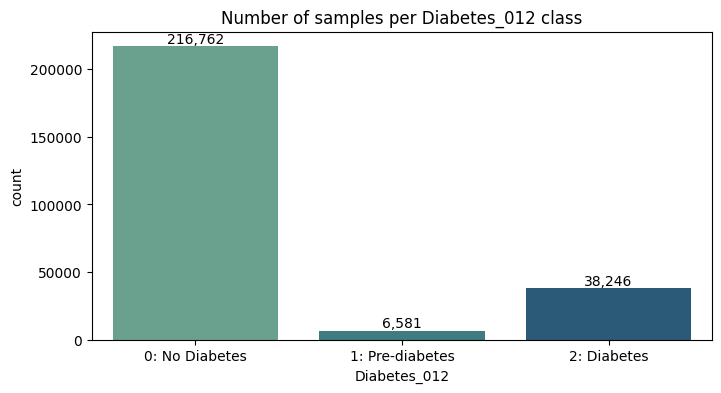

In [10]:
# number of samples per target class (0 = No Diabetes, 1 = Pre-diabetes, 2 = Diabetes)
plt.figure(figsize=(8, 4))
plt.title("Number of samples per Diabetes_012 class")
ax = sns.countplot(x=ds[target_col].astype(int), palette="crest")
ax.set_xticklabels(["0: No Diabetes", "1: Pre-diabetes", "2: Diabetes"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom")
plt.show()

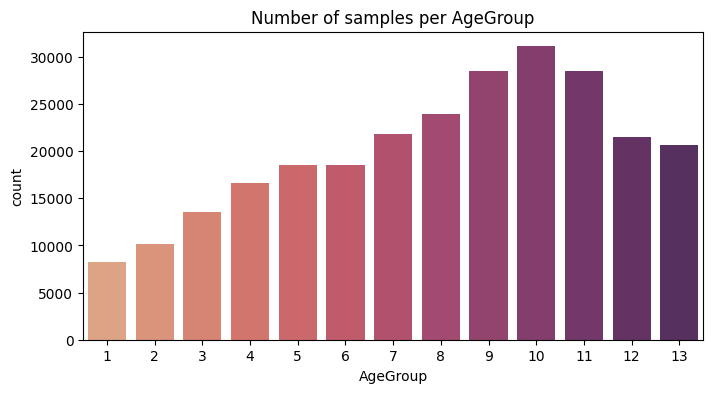

In [11]:
# number of samples per AgeGroup (1 = 18-24 ... 13 = 80+)
age_col = "AgeGroup" if "AgeGroup" in ds.columns else "Age"
plt.figure(figsize=(8, 4))
plt.title(f"Number of samples per {age_col}")
plt.xticks(rotation=0)
sns.countplot(x=ds[age_col].astype(int), palette="flare")
plt.show()

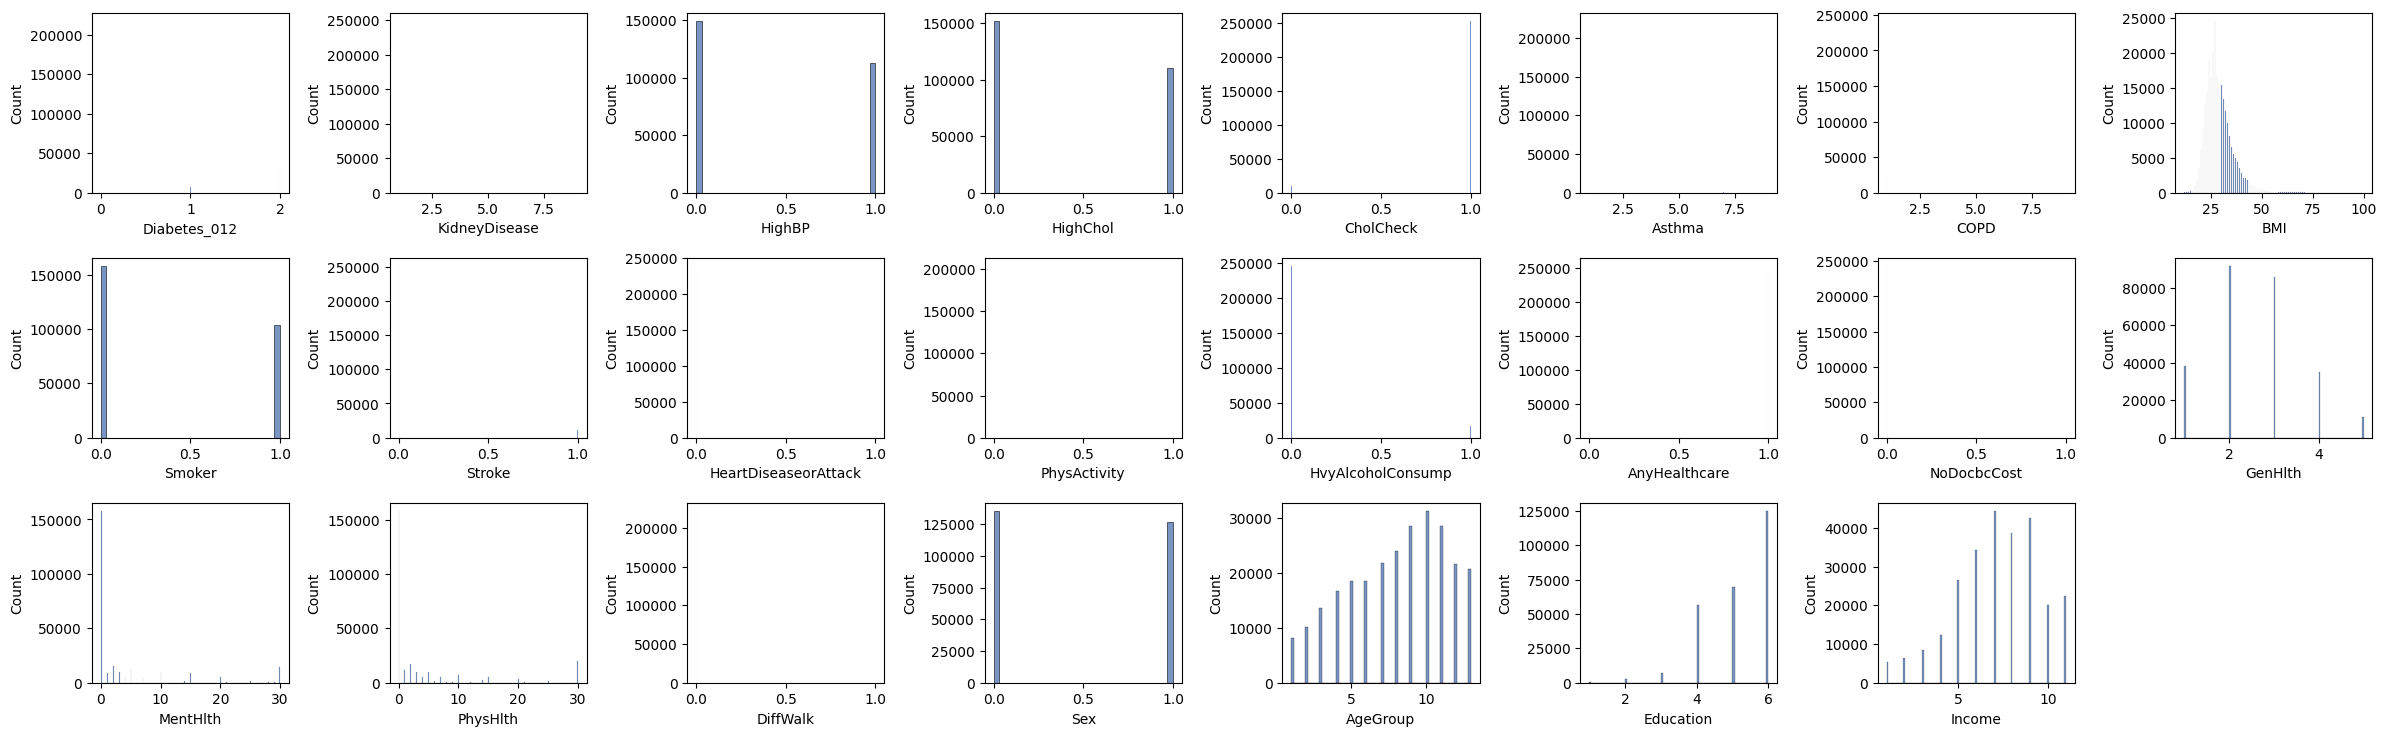

In [12]:
# distributions of the data
# use a copy of dataset for plotting
ds1 = ds.copy()
ds1.dropna(inplace=True)

num_of_cols = ds1.shape[1]
rows = 3
ncols = math.ceil(num_of_cols / rows)
fig, axes = plt.subplots(nrows=rows, ncols=ncols, figsize=(3 * ncols, 2.5 * rows))
for ax, col in zip(axes.flatten(), ds1.columns):
    sns.histplot(ds1[col], kde=False, ax=ax)

# hide any unused axes
for ax in axes.flatten()[num_of_cols:]:
    ax.set_visible(False)

plt.tight_layout(pad=1.2)
plt.show()
# click on the plot to see details

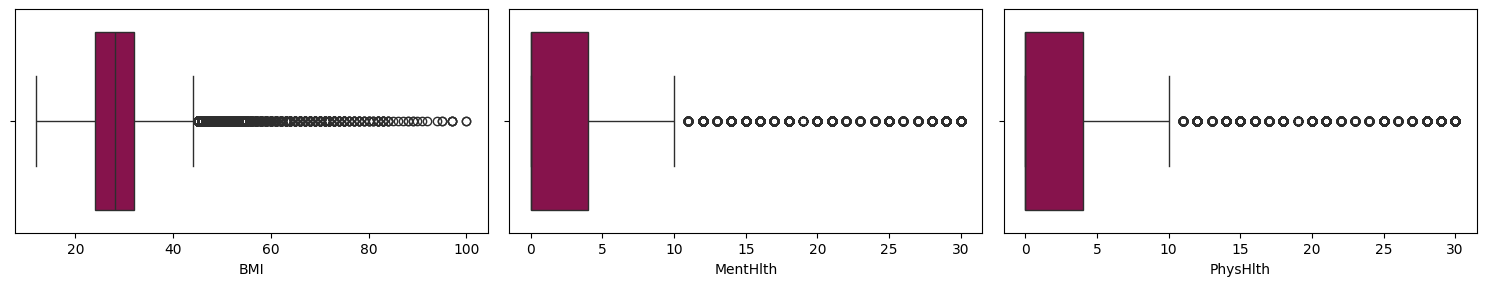

In [13]:
# boxplot for highlighting outliers in continuous numerical columns
num_of_cols = num_cols.shape[0]
rows = 1
fig, axes = plt.subplots(nrows=rows, ncols=num_of_cols, figsize=(5 * num_of_cols, 3))
axes_list = axes.flatten() if num_of_cols > 1 else [axes]
for ax, col in zip(axes_list, num_cols):
    sns.boxplot(x=ds[col], ax=ax, color='#99004c')

plt.tight_layout(pad=1.2)
plt.show()

<Figure size 1000x500 with 0 Axes>

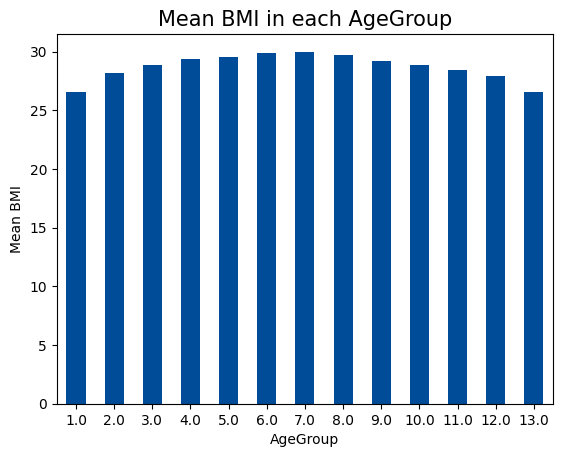

In [14]:
# mean BMI distribution in each AgeGroup
plt.figure(figsize=(10, 5))
a = ds.groupby(age_col).agg({'BMI': 'mean'})
a.plot(kind='bar', color='#004c99', legend=False)
plt.title(f'Mean BMI in each {age_col}', fontsize=15)
plt.xlabel(age_col, fontsize=10)
plt.ylabel('Mean BMI', fontsize=10)
plt.xticks(rotation=0)
plt.show()

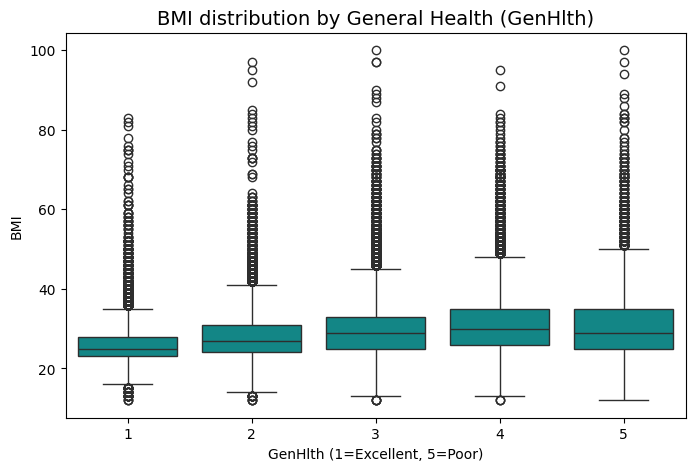

In [15]:
# BMI distribution across General Health ratings (1 = Excellent ... 5 = Poor)
plt.figure(figsize=(8, 5))
sns.boxplot(x=ds['GenHlth'].astype(int), y=ds['BMI'], color='#009999')
plt.title('BMI distribution by General Health (GenHlth)', fontsize=14)
plt.xlabel('GenHlth (1=Excellent, 5=Poor)')
plt.ylabel('BMI')
plt.show()

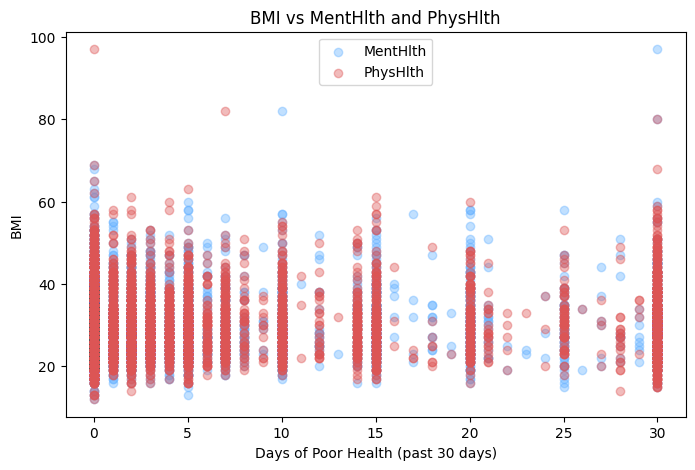

In [16]:
# comparing BMI based on MentHlth and PhysHlth (sampled for readability)
ds_sample = ds.sample(n=min(10000, len(ds)), random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(ds_sample['MentHlth'], ds_sample['BMI'], color='#66b2ff', alpha=0.4)
plt.scatter(ds_sample['PhysHlth'], ds_sample['BMI'], color='#DE5555', alpha=0.4)
plt.xlabel('Days of Poor Health (past 30 days)')
plt.xticks(range(0, 31, 5))
plt.ylabel('BMI')
plt.legend(labels=['MentHlth', 'PhysHlth'])
plt.title('BMI vs MentHlth and PhysHlth')
plt.show()

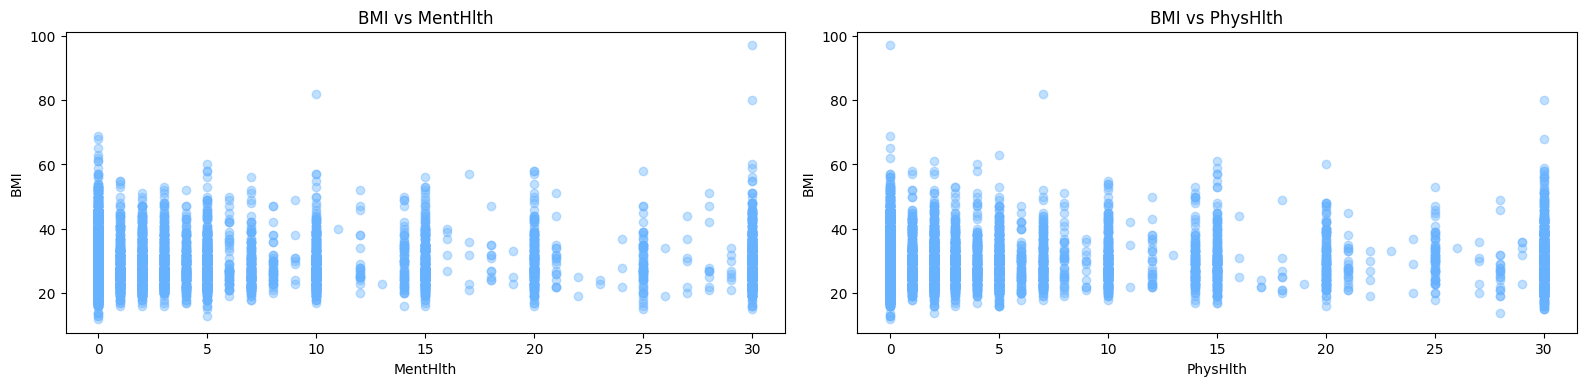

In [17]:
# comparing BMI based on MentHlth and PhysHlth separately
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 4))
cols = ['MentHlth', 'PhysHlth']
for i, col in enumerate(cols):
    axes[i].scatter(ds_sample[col], ds_sample['BMI'], color='#66b2ff', alpha=0.4)
    axes[i].set_xlabel(col)
    axes[i].set_xticks(range(0, 31, 5))
    axes[i].set_ylabel('BMI')
    axes[i].set_title(f'BMI vs {col}')
plt.tight_layout(pad=1.2)
plt.show()

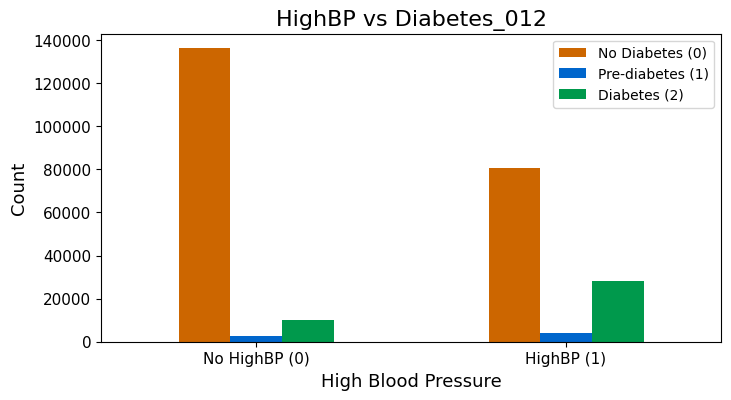

In [18]:
# comparison between HighBP and Diabetes_012
cmp_plot = pd.crosstab(ds['HighBP'].astype(int), ds[target_col].astype(int))
cmp_plot.index = ['No HighBP (0)', 'HighBP (1)']
cmp_plot.columns = ['No Diabetes (0)', 'Pre-diabetes (1)', 'Diabetes (2)']

cmp_plot.plot(kind='bar', stacked=False, color=['#CC6600', '#0066CC', '#00994C'], figsize=(8, 4))
plt.xlabel('High Blood Pressure', fontsize=13)
plt.ylabel('Count', fontsize=13)
plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)
plt.title('HighBP vs Diabetes_012', fontsize=16)
plt.show()

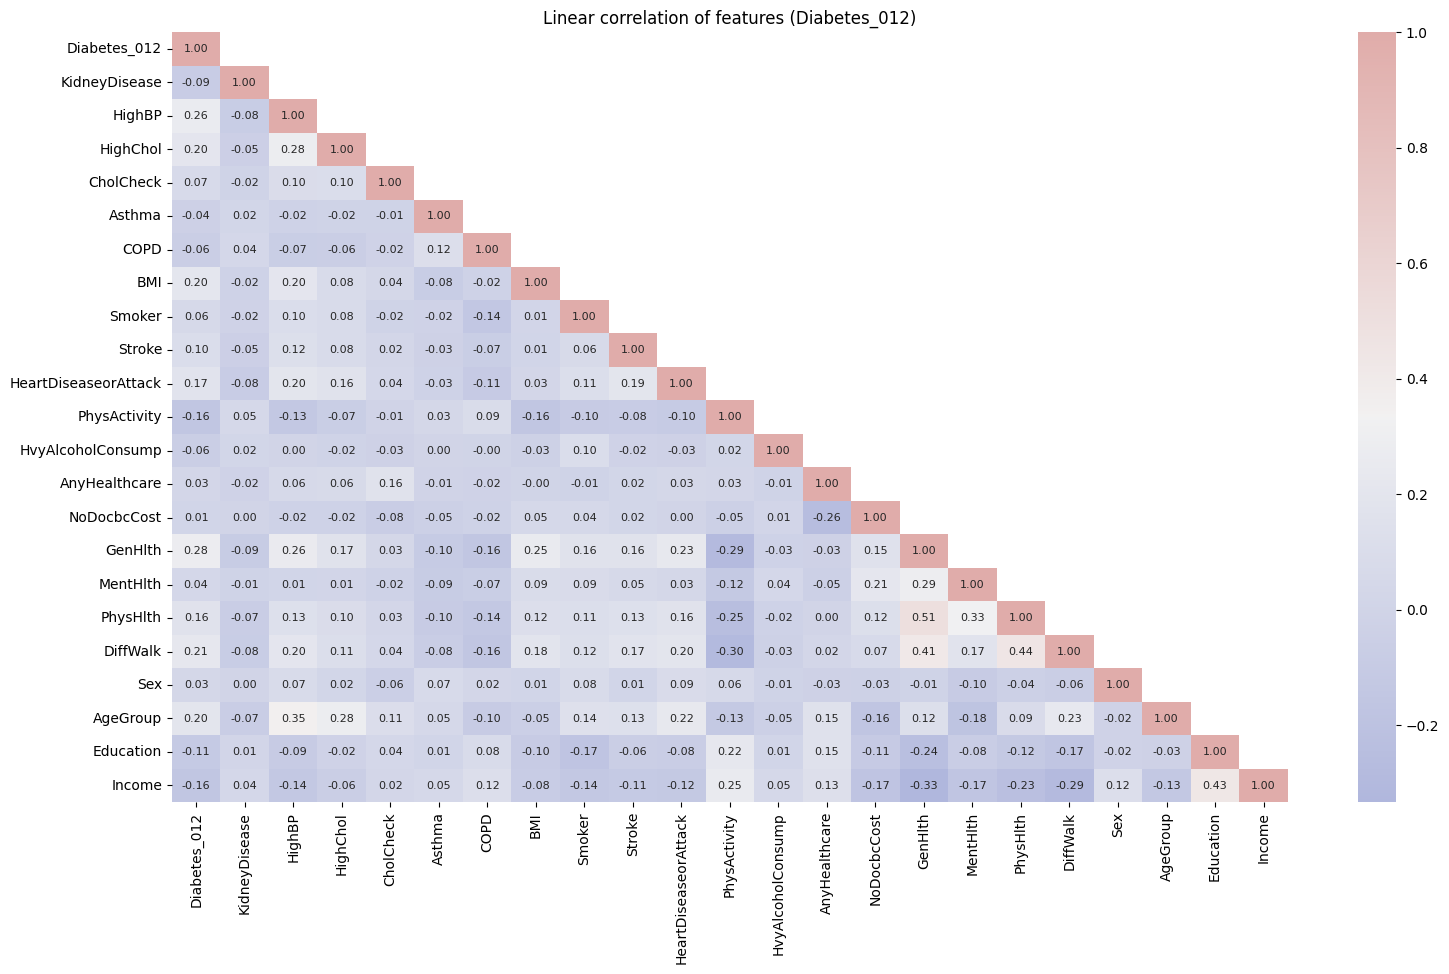

In [19]:
# linear correlation of all features
corrmat = ds.corr(numeric_only=True)
cmap = sns.diverging_palette(260, 15, s=50, l=75, n=6, as_cmap=True)
plt.figure(figsize=(18, 10))
sns.heatmap(
    corrmat,
    cmap=cmap,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    square=False,
    mask=~np.tril(np.ones((corrmat.shape[0], corrmat.shape[0]), dtype=bool))
)
plt.title("Linear correlation of features (Diabetes_012)")
plt.show()

# 3. Preprocessing

In [20]:
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.utils import resample
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [21]:
# Improved pipeline function for Diabetes_012 (3-class multiclass)
# Key upgrades for higher accuracy:
# 1. Domain feature engineering (BMI clipping, BMI*Age, BP*Chol, RiskCount, TotalUnhealthyDays)
# 2. Configurable balance_mode: 'none' (best accuracy ~84-85%), 'mild' (better macro-F1), 'equal' (1:1:1)
# 3. Full feature scaling across ALL numeric & ordinal features (fixes KNN/LR/MLP performance)
# 4. PCA applied to the full transformed feature matrix when enabled
def DiabetesDataPipeline(
        ds_dir=None,           # defaults to DATA_PATH loaded from kagglehub
        balance_mode='none',   # 'none', 'mild', or 'equal'
        drop_outlier=False,    # drop IQR outliers on continuous cols or not
        fill_na='median',      # 'median' or 'mean' for numerical imputation
        cat_encode='ordinal',  # 'ordinal' or 'onehot' encoding for categorical cols
        scale='norm',          # 'norm' (StandardScaler) or 'minmax' scaler
        feature_range=(0, 1),  # for minmax scaler
        pca_variance=None,     # pca variance ratio (e.g., 0.95) or None
        test_size=0.2,         # test size for train_test_split
        random_state=42        # random state for reproducibility
):
    if (
        balance_mode not in ['none', 'mild', 'equal']
        or fill_na not in ['median', 'mean']
        or cat_encode not in ['ordinal', 'onehot']
        or scale not in ['norm', 'minmax']
    ):
        raise ValueError("Invalid input")

    if ds_dir is None:
        ds_dir = DATA_PATH
    ds = pd.read_csv(ds_dir)
    target = "Diabetes_012"
    ds = ds.dropna(subset=[target]).drop_duplicates().copy()

    # --- Domain Feature Engineering ---
    age_col_name = 'AgeGroup' if 'AgeGroup' in ds.columns else 'Age'
    if 'BMI' in ds.columns:
        ds['BMI'] = ds['BMI'].clip(12, 60)
        if age_col_name in ds.columns:
            ds['BMI_x_Age'] = ds['BMI'] * ds[age_col_name]
    if {'HighBP', 'HighChol'}.issubset(ds.columns):
        ds['BP_x_Chol'] = ds['HighBP'] * ds['HighChol']
    risk_cols = [
        c for c in ['HighBP', 'HighChol', 'HeartDiseaseorAttack', 'Stroke', 'DiffWalk']
        if c in ds.columns
    ]
    if risk_cols:
        ds['RiskCount'] = ds[risk_cols].sum(axis=1)
    if {'MentHlth', 'PhysHlth'}.issubset(ds.columns):
        ds['TotalUnhealthyDays'] = ds['MentHlth'] + ds['PhysHlth']

    X = ds.drop(target, axis=1)
    y = ds[target].astype('int64')

    # Stratified split BEFORE any resampling/scaling/imputation to avoid data leakage
    x_train, x_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    # --- Optional Training-Only Class Balancing ---
    if balance_mode in ['mild', 'equal']:
        train_df = pd.concat([x_train, y_train], axis=1)
        c0 = train_df[train_df[target] == 0]
        c1 = train_df[train_df[target] == 1]
        c2 = train_df[train_df[target] == 2]

        if balance_mode == 'equal':
            target_n = len(c2)
            c0_s = resample(c0, replace=False, n_samples=min(len(c0), target_n), random_state=random_state)
            c1_s = resample(c1, replace=True, n_samples=target_n, random_state=random_state)
            train_balanced = pd.concat([c0_s, c1_s, c2])
        else:  # 'mild': keeps majority prior stronger while boosting rare class 1 moderately
            c0_s = resample(c0, replace=False, n_samples=min(len(c0), len(c2) * 2), random_state=random_state)
            c1_s = resample(c1, replace=True, n_samples=max(len(c1), len(c2) // 2), random_state=random_state)
            train_balanced = pd.concat([c0_s, c1_s, c2])

        train_balanced = train_balanced.sample(frac=1.0, random_state=random_state)
        x_train = train_balanced.drop(target, axis=1)
        y_train = train_balanced[target].astype('int64')

    # Separate numeric/ordinal scale-sensitive features from binary/categorical indicators
    num_ord_candidates = [
        'BMI', 'MentHlth', 'PhysHlth',
        'BMI_x_Age', 'RiskCount', 'TotalUnhealthyDays',
        age_col_name, 'GenHlth', 'Education', 'Income'
    ]
    continuous_cols = pd.Index([c for c in num_ord_candidates if c in x_train.columns])
    cat_cols = x_train.columns.drop(continuous_cols)

    if drop_outlier:
        for col in [c for c in ['BMI', 'MentHlth', 'PhysHlth'] if c in x_train.columns]:
            q1 = x_train[col].quantile(0.25)
            q3 = x_train[col].quantile(0.75)
            lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
            mask = x_train[col].isna() | ((x_train[col] >= lower) & (x_train[col] <= upper))
            x_train = x_train[mask]
            y_train = y_train[mask]
            mask_test = x_test[col].isna() | ((x_test[col] >= lower) & (x_test[col] <= upper))
            x_test = x_test[mask_test]
            y_test = y_test[mask_test]

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy=fill_na)),
        ("scaler", StandardScaler() if scale == 'norm' else MinMaxScaler(feature_range=feature_range)),
    ])

    if cat_encode == 'ordinal':
        categorical_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
            ("scaler", StandardScaler() if scale == 'norm' else MinMaxScaler(feature_range=feature_range)),
        ])
    else:
        categorical_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, continuous_cols),
            ("cat", categorical_transformer, cat_cols),
        ]
    )

    full_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("pca", PCA(n_components=pca_variance, random_state=random_state) if pca_variance is not None else "passthrough"),
    ])

    x_train = full_pipeline.fit_transform(x_train).astype(np.float32)
    x_test = full_pipeline.transform(x_test).astype(np.float32)

    return x_train, x_test, y_train, y_test

# 4. Modeling

The following preprocess configuration is selected (replacing `fill_na`, since BRFSS 2023 has no missing values, with `balance_mode` to compare peak accuracy vs. balanced macro-F1):

1. `balance_mode`: `"none"`, `"mild"`
2. `cat_encode`: `"ordinal"`, `"onehot"`
3. `pca_variance`: `0.95`, `None`

=> A total of $2 \cdot 2 \cdot 2 = 8$ meaningful preprocessing combinations

In [22]:
# 2^3 = 8 preprocess configs
preprocess_configs = [
    {
        "balance_mode": balance,
        "cat_encode": encode,
        "pca_variance": pca
    }
    for balance in ["none", "mild"]
    for encode in ["ordinal", "onehot"]
    for pca in [0.95, None]
]
print(preprocess_configs)

processed_data = []
for preprocess_config in preprocess_configs:
    X_train, X_test, y_train, y_test = DiabetesDataPipeline(**preprocess_config)
    processed_data.append((X_train, X_test, y_train, y_test))
print("Total preprocessed configs:", len(processed_data))
for cfg, (xt, xte, yt, yte) in zip(preprocess_configs, processed_data):
    print(f"  {cfg} -> train={xt.shape}, test={xte.shape}")

[{'balance_mode': 'none', 'cat_encode': 'ordinal', 'pca_variance': 0.95}, {'balance_mode': 'none', 'cat_encode': 'ordinal', 'pca_variance': None}, {'balance_mode': 'none', 'cat_encode': 'onehot', 'pca_variance': 0.95}, {'balance_mode': 'none', 'cat_encode': 'onehot', 'pca_variance': None}, {'balance_mode': 'mild', 'cat_encode': 'ordinal', 'pca_variance': 0.95}, {'balance_mode': 'mild', 'cat_encode': 'ordinal', 'pca_variance': None}, {'balance_mode': 'mild', 'cat_encode': 'onehot', 'pca_variance': 0.95}, {'balance_mode': 'mild', 'cat_encode': 'onehot', 'pca_variance': None}]
Total preprocessed configs: 8
  {'balance_mode': 'none', 'cat_encode': 'ordinal', 'pca_variance': 0.95} -> train=(194752, 20), test=(48688, 20)
  {'balance_mode': 'none', 'cat_encode': 'ordinal', 'pca_variance': None} -> train=(194752, 26), test=(48688, 26)
  {'balance_mode': 'none', 'cat_encode': 'onehot', 'pca_variance': 0.95} -> train=(194752, 16), test=(48688, 16)
  {'balance_mode': 'none', 'cat_encode': 'onehot

## Traditional ML models (`scikit-learn`, `xgboost`, & `lightgbm`)

Using tuned traditional ML models with 2 hyperparameter configurations each (for 3-class `Diabetes_012` classification):

1. K-Nearest Neighbors, `n_neighbors`: `25`, `51` (`weights="distance"`)
2. Logistic Regression, `penalty`: `None`, `"l2"` (`max_iter=500`)
3. Random Forest, `n_estimators`: `150`, `250` (`max_depth=14`, `min_samples_leaf=5`)
4. XGBoost, `learning_rate`: `0.05`, `0.1` (`n_estimators=350`, `max_depth=5`, `subsample=0.8`, `colsample_bytree=0.8`, `tree_method="hist"`)
5. LightGBM, `learning_rate`: `0.05`, `0.1` (`n_estimators=350`, `num_leaves=31`, `subsample=0.8`, `colsample_bytree=0.8`)

In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 5 types of ML models, each with 2 tuned configs
knn_config = [
    {"n_neighbors": n, "weights": "distance", "n_jobs": -1}
    for n in [25, 51]
]
logistic_config = [
    {"penalty": p, "max_iter": 500, "random_state": 42}
    for p in [None, "l2"]
]
forest_config = [
    {
        "n_estimators": n,
        "max_depth": 14,
        "min_samples_leaf": 5,
        "n_jobs": -1,
        "random_state": 42
    }
    for n in [150, 250]
]
boost_config = [
    {
        "learning_rate": lr,
        "n_estimators": 350,
        "max_depth": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 5,
        "reg_lambda": 2.0,
        "objective": "multi:softprob",
        "num_class": 3,
        "eval_metric": "mlogloss",
        "tree_method": "hist",
        "n_jobs": -1,
        "random_state": 42
    }
    for lr in [0.05, 0.1]
]
lgbm_config = [
    {
        "learning_rate": lr,
        "n_estimators": 350,
        "num_leaves": 31,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_samples": 30,
        "objective": "multiclass",
        "num_class": 3,
        "n_jobs": -1,
        "random_state": 42,
        "verbose": -1
    }
    for lr in [0.05, 0.1]
]

models = {
    'K-Nearest Neighbors': (KNeighborsClassifier, knn_config),
    'Logistic Regression': (LogisticRegression, logistic_config),
    'Random Forest': (RandomForestClassifier, forest_config),
    'XGBoost': (XGBClassifier, boost_config),
    'LightGBM': (LGBMClassifier, lgbm_config),
}

Train multiple tuned traditional ML model configurations across all 8 preprocessing setups

In [24]:
model_result = pd.DataFrame(columns=[
    "classifier",
    "model_config",
    "balance_mode",
    "encode",
    "pca",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "f1_weighted"
])

# Train and evaluate
if TRAIN_MODEL:
    for name, (classifier, model_configs) in models.items():
        print(f"Training {name}...")
        start_time = time.time()

        for model_config in model_configs:
            for data_config, data_splited in zip(preprocess_configs, processed_data):
                X_train, X_test, y_train, y_test = data_splited
                model = classifier(**model_config)
                model.fit(X_train, y_train)

                y_pred = model.predict(X_test)

                accuracy = accuracy_score(y_test, y_pred)
                precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
                recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
                f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
                f1_w = f1_score(y_test, y_pred, average="weighted", zero_division=0)

                model_result.loc[len(model_result)] = [
                    name,
                    list(model_config.values())[0],
                    *data_config.values(),
                    accuracy, precision, recall, f1, f1_w
                ]

                print(".", end='', flush=True)
        end_time = time.time()
        elapsed_time = int(end_time - start_time)
        print(f"\nElapsed time: {elapsed_time // 60} minutes {elapsed_time % 60} seconds\n")
else:
    print("Training skipped.")

Training K-Nearest Neighbors...
................
Elapsed time: 13 minutes 48 seconds

Training Logistic Regression...
................
Elapsed time: 1 minutes 2 seconds

Training Random Forest...
................
Elapsed time: 31 minutes 11 seconds

Training XGBoost...
................
Elapsed time: 6 minutes 18 seconds

Training LightGBM...
................
Elapsed time: 5 minutes 8 seconds



## Deep learning MLP model (`pytorch`)

In [25]:
BATCH_SIZE = 256
NUM_EPOCH = 20
NUM_CLASSES = 3

Define the regularized 3-class MLP architecture (BatchNorm + Dropout):

In [26]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using PyTorch device:", device)


class MLP(nn.Module):
    def __init__(self, in_dim, num_classes=3, num_hidden=2, dropout=0.2):
        super().__init__()
        if num_hidden not in [2, 3]:
            raise ValueError("num_hidden must be 2 or 3.")

        if num_hidden == 2:
            self.sequence = nn.Sequential(
                nn.Linear(in_dim, 128),
                nn.BatchNorm1d(128),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(128, 64),
                nn.BatchNorm1d(64),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(64, num_classes),
            )
        elif num_hidden == 3:
            self.sequence = nn.Sequential(
                nn.Linear(in_dim, 128),
                nn.BatchNorm1d(128),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(128, 64),
                nn.BatchNorm1d(64),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(64, 32),
                nn.BatchNorm1d(32),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(32, num_classes),
            )

    def forward(self, x):
        return self.sequence(x)

Using PyTorch device: cpu


Implement the Dataset for the model:

In [27]:
from torch.utils.data import DataLoader, Dataset


class MyDataset(Dataset):
    def __init__(self, features, labels):
        super().__init__()
        self.features = features
        self.labels = labels

    def __len__(self):
        return self.features.shape[0]

    def __getitem__(self, idx):
        X = torch.from_numpy(self.features[idx]).float()   # float32 features
        y = torch.tensor(self.labels[idx], dtype=torch.long)  # int64 class index (0, 1, 2)
        return X, y

Utility functions (train and evaluate)

In [28]:
def train_loop(dataloader, model, loss_fn, optimizer):
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


def test_loop(dataloader, model, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0.0, 0
    all_preds = []

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            pred_class = pred.argmax(dim=1)
            correct += (pred_class == y).sum().item()
            all_preds.append(pred_class.cpu().numpy())

    test_loss /= num_batches
    correct /= size
    return np.concatenate(all_preds), correct, test_loss

Train multiple MLP configurations (2 hidden layers vs 3 hidden layers across all 8 preprocessing configs)

In [29]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

mlp_hidden_choice = [2, 3]

if TRAIN_MODEL:
    print("Training MLP...")
    start_time = time.time()

    for num_hidden in mlp_hidden_choice:
        for data_config, data_splited in zip(preprocess_configs, processed_data):
            X_train, X_test, y_train, y_test = data_splited

            if not isinstance(X_train, np.ndarray):
                X_train = X_train.toarray()
                X_test = X_test.toarray()

            y_train_np = y_train.to_numpy()
            y_test_np = y_test.to_numpy()

            train_set = MyDataset(X_train, y_train_np)
            test_set = MyDataset(X_test, y_test_np)
            train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
            test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

            torch.manual_seed(42)
            model = MLP(in_dim=X_train.shape[-1], num_classes=NUM_CLASSES, num_hidden=num_hidden).to(device)
            loss_fn = nn.CrossEntropyLoss()
            optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
            scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCH)

            for epoch in range(NUM_EPOCH):
                train_loop(train_loader, model, loss_fn, optimizer)
                scheduler.step()

            y_pred, _, _ = test_loop(test_loader, model, loss_fn)

            accuracy = accuracy_score(y_test_np, y_pred)
            precision = precision_score(y_test_np, y_pred, average="macro", zero_division=0)
            recall = recall_score(y_test_np, y_pred, average="macro", zero_division=0)
            f1 = f1_score(y_test_np, y_pred, average="macro", zero_division=0)
            f1_w = f1_score(y_test_np, y_pred, average="weighted", zero_division=0)

            model_result.loc[len(model_result)] = [
                "MLP",
                num_hidden,
                *data_config.values(),
                accuracy, precision, recall, f1, f1_w
            ]

            print(".", end="", flush=True)

    end_time = time.time()
    elapsed_time = int(end_time - start_time)
    print(f"\nElapsed time: {elapsed_time // 60} minutes {elapsed_time % 60} seconds\n")
else:
    print("Training skipped.")

Training MLP...
................
Elapsed time: 24 minutes 13 seconds



In [ ]:
RESULTS_CSV = "model_result_diabetes_012_v3.csv"
if TRAIN_MODEL:
    model_result.to_csv(RESULTS_CSV, index=False)
    print(f"Saved results to {RESULTS_CSV}")

In [ ]:
# Load saved results if TRAIN_MODEL is False
if not TRAIN_MODEL:
    if os.path.exists(RESULTS_CSV):
        model_result = pd.read_csv(RESULTS_CSV)
        print(f"Loaded results from {RESULTS_CSV}")
    else:
        raise FileNotFoundError(
            f"{RESULTS_CSV} not found. Set TRAIN_MODEL = True to train and generate results first."
        )

In [ ]:
model_result.info()

In [ ]:
model_result = model_result.fillna("None")

In [ ]:
def highlight_row(row, idx):
    if row.name == idx:
        return ["background-color: yellow"] * len(row)
    else:
        return [""] * len(row)

Selecting best configurations for each type of model (by **Accuracy** and by **Macro F1-score**)

In [35]:
from IPython.display import display

model_names = [*models.keys(), "MLP"]
model_max_acc = []
model_max_f1 = []

for name in model_names:
    df_result = model_result[model_result["classifier"] == name]
    max_acc_row_idx = df_result["accuracy"].idxmax()
    max_f1_row_idx = df_result["f1"].idxmax()
    model_max_acc.append(max_acc_row_idx)
    model_max_f1.append(max_f1_row_idx)

    styled_result = df_result.style.apply(highlight_row, axis=1, idx=max_acc_row_idx)

    print(f"{name} result (highlighted = highest accuracy):")
    display(styled_result)

    cfg_param = "num_hidden" if name == "MLP" else list(models[name][1][0].keys())[0]
    print(f"=> Best ACCURACY for {name}: {df_result.loc[max_acc_row_idx, 'accuracy']:.4f} (f1_macro={df_result.loc[max_acc_row_idx, 'f1']:.4f}, f1_weighted={df_result.loc[max_acc_row_idx, 'f1_weighted']:.4f})")
    print(f"   - {cfg_param}: {df_result.loc[max_acc_row_idx, 'model_config']} | balance_mode: {df_result.loc[max_acc_row_idx, 'balance_mode']} | encode: {df_result.loc[max_acc_row_idx, 'encode']} | pca: {df_result.loc[max_acc_row_idx, 'pca']}")
    print(f"=> Best MACRO F1 for {name}: {df_result.loc[max_f1_row_idx, 'f1']:.4f} (accuracy={df_result.loc[max_f1_row_idx, 'accuracy']:.4f})")
    print(f"   - {cfg_param}: {df_result.loc[max_f1_row_idx, 'model_config']} | balance_mode: {df_result.loc[max_f1_row_idx, 'balance_mode']} | encode: {df_result.loc[max_f1_row_idx, 'encode']} | pca: {df_result.loc[max_f1_row_idx, 'pca']}")
    print()

K-Nearest Neighbors result (highlighted = highest accuracy):


,classifier,model_config,balance_mode,encode,pca,accuracy,precision,recall,f1,f1_weighted
0,K-Nearest Neighbors,25,none,ordinal,0.950000,0.812028,0.427048,0.375243,0.377756,0.768092
1,K-Nearest Neighbors,25,none,ordinal,None,0.812541,0.428443,0.375239,0.377785,0.768336
2,K-Nearest Neighbors,25,none,onehot,0.950000,0.812151,0.424887,0.372413,0.373789,0.766565
3,K-Nearest Neighbors,25,none,onehot,None,0.814102,0.432149,0.374631,0.376973,0.768674
4,K-Nearest Neighbors,25,mild,ordinal,0.950000,0.740757,0.429868,0.454487,0.437865,0.757732
5,K-Nearest Neighbors,25,mild,ordinal,None,0.740573,0.428713,0.453027,0.436519,0.757687
6,K-Nearest Neighbors,25,mild,onehot,0.950000,0.737019,0.426210,0.450475,0.433797,0.754797
7,K-Nearest Neighbors,25,mild,onehot,None,0.741209,0.428118,0.451383,0.435670,0.757934
8,K-Nearest Neighbors,51,none,ordinal,0.950000,0.813650,0.429705,0.369008,0.369030,0.764833
9,K-Nearest Neighbors,51,none,ordinal,None,0.814349,0.431824,0.369470,0.369670,0.765460


=> Best ACCURACY for K-Nearest Neighbors: 0.8153 (f1_macro=0.3669, f1_weighted=0.7647)
   - n_neighbors: 51 | balance_mode: none | encode: onehot | pca: None
=> Best MACRO F1 for K-Nearest Neighbors: 0.4412 (accuracy=0.7628)
   - n_neighbors: 51 | balance_mode: mild | encode: ordinal | pca: None

Logistic Regression result (highlighted = highest accuracy):


,classifier,model_config,balance_mode,encode,pca,accuracy,precision,recall,f1,f1_weighted
16,Logistic Regression,None,none,ordinal,0.950000,0.820736,0.450089,0.380857,0.385315,0.775167
17,Logistic Regression,None,none,ordinal,None,0.821291,0.451736,0.382861,0.388030,0.776615
18,Logistic Regression,None,none,onehot,0.950000,0.820017,0.447480,0.379390,0.383263,0.773976
19,Logistic Regression,None,none,onehot,None,0.821558,0.452675,0.383609,0.389054,0.777169
20,Logistic Regression,None,mild,ordinal,0.950000,0.782719,0.464102,0.457171,0.439229,0.781038
21,Logistic Regression,None,mild,ordinal,None,0.783561,0.482297,0.461273,0.443005,0.782437
22,Logistic Regression,None,mild,onehot,0.950000,0.781240,0.424254,0.457499,0.437967,0.780148
23,Logistic Regression,None,mild,onehot,None,0.783643,0.478107,0.461652,0.444351,0.782644
24,Logistic Regression,l2,none,ordinal,0.950000,0.820736,0.450089,0.380857,0.385315,0.775167
25,Logistic Regression,l2,none,ordinal,None,0.821291,0.451736,0.382861,0.388030,0.776615


=> Best ACCURACY for Logistic Regression: 0.8216 (f1_macro=0.3891, f1_weighted=0.7772)
   - penalty: None | balance_mode: none | encode: onehot | pca: None
=> Best MACRO F1 for Logistic Regression: 0.4444 (accuracy=0.7838)
   - penalty: l2 | balance_mode: mild | encode: onehot | pca: None

Random Forest result (highlighted = highest accuracy):


,classifier,model_config,balance_mode,encode,pca,accuracy,precision,recall,f1,f1_weighted
32,Random Forest,150,none,ordinal,0.950000,0.823262,0.466679,0.370013,0.369625,0.769084
33,Random Forest,150,none,ordinal,None,0.824947,0.469010,0.377811,0.381311,0.775088
34,Random Forest,150,none,onehot,0.950000,0.821434,0.454971,0.368877,0.367887,0.767708
35,Random Forest,150,none,onehot,None,0.824351,0.469890,0.374368,0.376300,0.772492
36,Random Forest,150,mild,ordinal,0.950000,0.780726,0.462458,0.461303,0.440266,0.780510
37,Random Forest,150,mild,ordinal,None,0.781342,0.477078,0.465281,0.443378,0.781801
38,Random Forest,150,mild,onehot,0.950000,0.776680,0.423796,0.462145,0.438596,0.778019
39,Random Forest,150,mild,onehot,None,0.784012,0.504738,0.463526,0.443610,0.783184
40,Random Forest,250,none,ordinal,0.950000,0.823119,0.465977,0.369635,0.369033,0.768769
41,Random Forest,250,none,ordinal,None,0.824926,0.469291,0.377589,0.381002,0.774924


... (3 outputs left out)

,classifier,model_config,balance_mode,encode,pca,accuracy,precision,recall,f1,f1_weighted
64,LightGBM,0.050000,none,ordinal,0.950000,0.823119,0.458719,0.380976,0.385638,0.776321
65,LightGBM,0.050000,none,ordinal,None,0.825398,0.465021,0.387736,0.394857,0.781397
66,LightGBM,0.050000,none,onehot,0.950000,0.822482,0.455719,0.379614,0.383658,0.775257
67,LightGBM,0.050000,none,onehot,None,0.825337,0.464739,0.387995,0.395189,0.781522
68,LightGBM,0.050000,mild,ordinal,0.950000,0.776762,0.457494,0.466069,0.443090,0.778961
69,LightGBM,0.050000,mild,ordinal,None,0.778796,0.456054,0.468989,0.446221,0.781123
70,LightGBM,0.050000,mild,onehot,0.950000,0.774031,0.446067,0.464392,0.440335,0.776806
71,LightGBM,0.050000,mild,onehot,None,0.779412,0.454608,0.470630,0.447017,0.781818
72,LightGBM,0.100000,none,ordinal,0.950000,0.822585,0.456613,0.383175,0.388606,0.777379
73,LightGBM,0.100000,none,ordinal,None,0.825070,0.519308,0.388203,0.395615,0.781439


=> Best ACCURACY for LightGBM: 0.8254 (f1_macro=0.3949, f1_weighted=0.7814)
   - learning_rate: 0.05 | balance_mode: none | encode: ordinal | pca: None
=> Best MACRO F1 for LightGBM: 0.4470 (accuracy=0.7794)
   - learning_rate: 0.05 | balance_mode: mild | encode: onehot | pca: None

MLP result (highlighted = highest accuracy):


,classifier,model_config,balance_mode,encode,pca,accuracy,precision,recall,f1,f1_weighted
80,MLP,2,none,ordinal,0.950000,0.824536,0.462875,0.385749,0.392193,0.779811
81,MLP,2,none,ordinal,None,0.824289,0.461503,0.386892,0.393644,0.780362
82,MLP,2,none,onehot,0.950000,0.822708,0.456070,0.382514,0.387640,0.777112
83,MLP,2,none,onehot,None,0.824577,0.462118,0.388325,0.395523,0.781317
84,MLP,2,mild,ordinal,0.950000,0.777481,0.455508,0.469910,0.446171,0.780339
85,MLP,2,mild,ordinal,None,0.774256,0.459376,0.472667,0.447947,0.778672
86,MLP,2,mild,onehot,0.950000,0.774873,0.446379,0.468039,0.442917,0.778272
87,MLP,2,mild,onehot,None,0.777235,0.455080,0.471244,0.449299,0.780694
88,MLP,3,none,ordinal,0.950000,0.824556,0.468835,0.375554,0.378010,0.773432
89,MLP,3,none,ordinal,None,0.825193,0.468707,0.380080,0.384564,0.776646


=> Best ACCURACY for MLP: 0.8252 (f1_macro=0.3846, f1_weighted=0.7766)
   - num_hidden: 3 | balance_mode: none | encode: ordinal | pca: None
=> Best MACRO F1 for MLP: 0.4493 (accuracy=0.7772)
   - num_hidden: 2 | balance_mode: mild | encode: onehot | pca: None



Comparing the best configurations of each model type against each other (Highest **Accuracy** & Highest **Macro F1**):

In [36]:
# 1. Comparison by highest Accuracy
max_acc_models = model_result.loc[model_max_acc]
best_acc_idx = max_acc_models["accuracy"].idxmax()
print(f"Highest ACCURACY model: {model_result.loc[best_acc_idx, 'classifier']} ({model_result.loc[best_acc_idx, 'accuracy']:.4f})")
display(max_acc_models.style.apply(highlight_row, axis=1, idx=best_acc_idx))

print()

# 2. Comparison by highest Macro F1-score
max_f1_models = model_result.loc[model_max_f1]
best_f1_idx = max_f1_models["f1"].idxmax()
print(f"Highest MACRO F1 model: {model_result.loc[best_f1_idx, 'classifier']} ({model_result.loc[best_f1_idx, 'f1']:.4f})")
display(max_f1_models.style.apply(highlight_row, axis=1, idx=best_f1_idx))

Highest ACCURACY model: XGBoost (0.8255)


,classifier,model_config,balance_mode,encode,pca,accuracy,precision,recall,f1,f1_weighted
11,K-Nearest Neighbors,51,none,onehot,None,0.815314,0.433972,0.367660,0.366887,0.764689
19,Logistic Regression,None,none,onehot,None,0.821558,0.452675,0.383609,0.389054,0.777169
33,Random Forest,150,none,ordinal,None,0.824947,0.469010,0.377811,0.381311,0.775088
49,XGBoost,0.050000,none,ordinal,None,0.825542,0.466545,0.386372,0.393136,0.780649
65,LightGBM,0.050000,none,ordinal,None,0.825398,0.465021,0.387736,0.394857,0.781397
89,MLP,3,none,ordinal,None,0.825193,0.468707,0.380080,0.384564,0.776646



Highest MACRO F1 model: MLP (0.4493)


,classifier,model_config,balance_mode,encode,pca,accuracy,precision,recall,f1,f1_weighted
13,K-Nearest Neighbors,51,mild,ordinal,None,0.762837,0.433844,0.457386,0.441174,0.770334
31,Logistic Regression,l2,mild,onehot,None,0.783787,0.478186,0.461639,0.444410,0.782735
39,Random Forest,150,mild,onehot,None,0.784012,0.504738,0.463526,0.443610,0.783184
63,XGBoost,0.100000,mild,onehot,None,0.777522,0.454740,0.469761,0.448591,0.780688
71,LightGBM,0.050000,mild,onehot,None,0.779412,0.454608,0.470630,0.447017,0.781818
87,MLP,2,mild,onehot,None,0.777235,0.455080,0.471244,0.449299,0.780694
